In [1]:
import numpy as np
import scipy.io as sio
from scipy.ndimage import zoom

print("开始制作 TF 训练专用光源数据集...")

mat_data = sio.loadmat('VCSEL_Initial_Field.mat')
E_mat = mat_data['E_initial']

scale_factor = 100 / E_mat.shape[0]
E_real_resized = zoom(np.real(E_mat), scale_factor)
E_imag_resized = zoom(np.imag(E_mat), scale_factor)

E_resized = (E_real_resized + 1j * E_imag_resized).astype(np.complex64)

save_name = 'vcsel_100x100_source.npy'
np.save(save_name, E_resized)

print(f"搞定！真实光场已永久保存为: {save_name}")
print("你可以随时在任何深度学习代码里直接加载它了！")

开始制作 TF 训练专用光源数据集...
搞定！真实光场已永久保存为: vcsel_100x100_source.npy
你可以随时在任何深度学习代码里直接加载它了！


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from sklearn.model_selection import train_test_split
from PIL import Image
from scipy.special import eval_genlaguerre
from skimage import io, color, transform
import tensorflow as tf
from PIL import Image
from pathlib import Path

开始计算 VCSEL 面到相位板面的 150um 自由空间传播...
读取初始光场 shape: (100, 100)
读取初始光场 dtype: complex64
📡 正在 1024x1024 网格下传播 150.0 um...
传播后光场 shape: (100, 100)
传播后光场 dtype: complex64
传播后总能量: 10000.0
✅ 完成！150um 后的相位板面复光场已保存为: vcsel_150um_ComplexField_100x100.npy


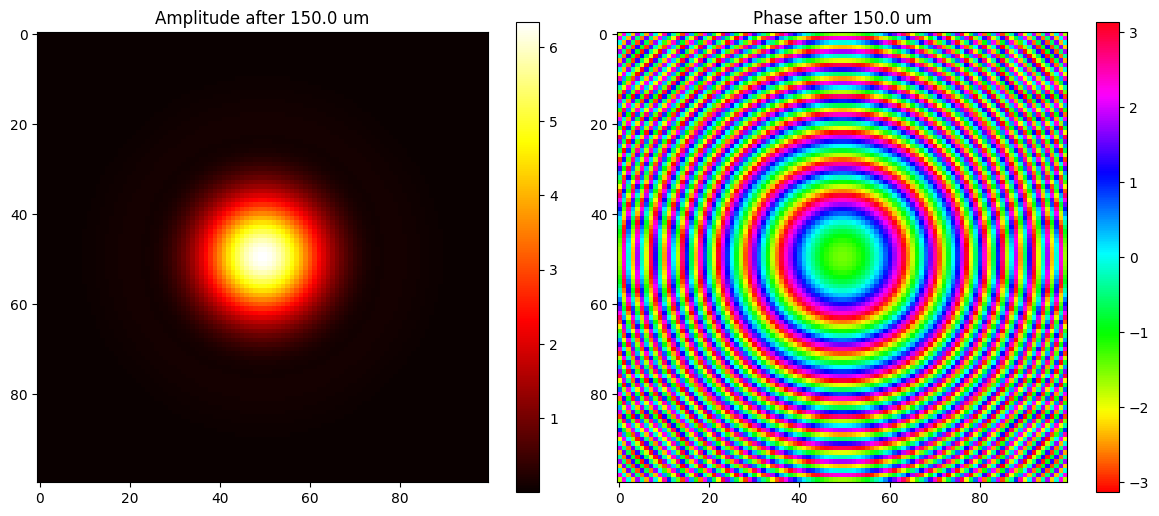

In [9]:
    import numpy as np
    import matplotlib.pyplot as plt
    
    print("开始计算 VCSEL 面到相位板面的 150um 自由空间传播...")
    
    # ==========================================
    # 1. 加载已经修正好的 100x100 VCSEL 初始复光场
    # ==========================================
    source_path = 'vcsel_100x100_source.npy'
    E_source = np.load(source_path)
    
    print("读取初始光场 shape:", E_source.shape)
    print("读取初始光场 dtype:", E_source.dtype)
    
    # 检查尺寸是否正确
    if E_source.shape != (100, 100):
        raise ValueError(f"输入光场尺寸不是 100x100，而是 {E_source.shape}，请检查源文件。")
    
    # 转成高精度复数，方便后续传播计算
    E_source = E_source.astype(np.complex128)
    
    # ==========================================
    # 2. 设置物理参数
    # ==========================================
    lam = 0.850      # 波长，单位 um
    z_vcsel = 150.0   # VCSEL 面到相位板面的距离，单位 um
    n_medium = 1.0    # 空气中传播
    
    dx = 1.0          # 当前 100x100 光场的像素尺寸，单位 um/pixel
    dy = dx
    
    N = 100           # 原始光场尺寸
    
    # ==========================================
    # 3. Padding，防止 FFT 传播时边界卷绕
    # ==========================================
    # 这里不再使用旧代码的 8192 和 0.025um/pixel。
    # 现在输入就是 100x100, 1um/pixel。
    # padding 后物理像素尺寸仍然是 1um/pixel，只是计算画布变大。
    N_pad = 1024
    
    E_padded = np.zeros((N_pad, N_pad), dtype=np.complex128)
    
    start_idx = (N_pad - N) // 2
    E_padded[start_idx:start_idx+N, start_idx:start_idx+N] = E_source
    
    print(f"📡 正在 {N_pad}x{N_pad} 网格下传播 {z_vcsel} um...")
    
    # ==========================================
    # 4. 角谱法自由空间传播
    # ==========================================
    fx = np.fft.fftfreq(N_pad, d=dx)
    fy = np.fft.fftfreq(N_pad, d=dy)
    
    fxx, fyy = np.meshgrid(fx, fy)
    
    # kz = sqrt((n/lambda)^2 - fx^2 - fy^2)
    # 加 0j 是为了允许出现复数 kz，即处理倏逝波
    kz = np.sqrt((n_medium / lam)**2 - fxx**2 - fyy**2 + 0j)
    
    H = np.exp(1j * 2 * np.pi * kz * z_vcsel)
    
    E_f = np.fft.fft2(E_padded)
    E_out_padded = np.fft.ifft2(E_f * H)
    
    # ==========================================
    # 5. 从传播后的大画布中截取中心 100x100 区域
    # ==========================================
    E_out_100x100 = E_out_padded[start_idx:start_idx+N, start_idx:start_idx+N]
    
    # ==========================================
    # 6. 能量归一化
    # ==========================================
    # 如果你的 DNN 后续代码默认总能量是 10000，就保留这段。
    # 如果后续代码不需要这个归一化，可以删掉这一段。
    current_energy = np.sum(np.abs(E_out_100x100)**2)
    
    if current_energy == 0:
        raise ValueError("传播后的光场能量为 0，请检查输入光场。")
    
    scaling_factor = np.sqrt(10000.0 / current_energy)
    E_final = (E_out_100x100 * scaling_factor).astype(np.complex64)
    
    print("传播后光场 shape:", E_final.shape)
    print("传播后光场 dtype:", E_final.dtype)
    print("传播后总能量:", np.sum(np.abs(E_final)**2))
    
    # ==========================================
    # 7. 保存最终相位板面复光场
    # ==========================================
    save_name = 'vcsel_150um_ComplexField_100x100.npy'
    np.save(save_name, E_final)
    
    print(f"✅ 完成！150um 后的相位板面复光场已保存为: {save_name}")
    
    # ==========================================
    # 8. 画图验证
    # ==========================================
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(np.abs(E_final), cmap='hot')
    plt.title(f"Amplitude after {z_vcsel} um")
    plt.colorbar()
    
    plt.subplot(1, 2, 2)
    plt.imshow(np.angle(E_final), cmap='hsv')
    plt.title(f"Phase after {z_vcsel} um")
    plt.colorbar()
    
    plt.tight_layout()
    plt.show()

In [2]:
Ns = 300           # 总视场大小 300x300 像素 
dx = 1.0           # 像素大小 1 um
lam = 0.850        # 波长0.798  nm = 0.798 um 
z = 1000.0         # 传播距离 1000 um (先设为1000测试)
n = 1.0            # 环境折射率 (空气设为 1.0)

In [3]:
def Propagation(E, Ns, lam, z, n=1.0, dx=1.0): 
    # E: 输入复振幅光场 (TensorFlow 张量)
    # Ns: 光场大小 (例如 300)
    # lam: 波长 (0.798 um)
    # z: 传播距离 (1000 um)
    # n: 介质折射率 (默认1.0)
    # dx: 像素尺寸 (默认1.0 um)
    
    lam_n = lam / n           # 介质中的波长
    
    # 1. 生成频域坐标系 
    fx = np.fft.fftshift(np.fft.fftfreq(Ns, d=dx))
    fxx, fyy = np.meshgrid(fx, fx)
    
    # 2. 计算 kz 的内部参数
    argument = (2 * np.pi)**2 * ((1. / lam_n) ** 2 - fxx ** 2 - fyy ** 2)

    # 3. 区分传播波和隐失波 
    tmp = np.sqrt(np.abs(argument))
    kz = np.where(argument >= 0, tmp, 1j * tmp)
    
    # 4. 计算角谱传递函数 H = exp(j * kz * z)
    H = np.exp(1j * kz * z)
    H_tf = tf.cast(H, tf.complex64)

    # 5. 傅里叶变换到频域
    fft_c = tf.signal.fft2d(E)
    c = tf.signal.fftshift(fft_c)
    
    # 6. 频域传播 (张量相乘)
    U_f = c * H_tf
    
    # 7. 逆傅里叶变换回空域
    Field = tf.signal.ifft2d(tf.signal.ifftshift(U_f))
    
    return Field

In [4]:
def Propagation_1(E, Ns, lam, z, n=1.0, dx=1.0): 
    lam_n = lam / n
    
    fx = np.fft.fftshift(np.fft.fftfreq(Ns, d=dx))
    fxx, fyy = np.meshgrid(fx, fx)
    argument = (2 * np.pi)**2 * ((1. / lam_n) ** 2 - fxx ** 2 - fyy ** 2)

    tmp = np.sqrt(np.abs(argument))
    kz = np.where(argument >= 0, tmp, 1j * tmp)
    
    # 计算传递函数
    H = np.exp(1j * kz * z)

    # NumPy 傅里叶变换
    fft_c = np.fft.fft2(E)
    c = np.fft.fftshift(fft_c)

    # 频域相乘并逆傅里叶变换
    Field = np.fft.ifft2(np.fft.ifftshift(c * H))
    
    return Field

相位板尺寸: 100 × 100
板中心间距: 100 um
传播窗口: 800 × 800
连续相位训练: 2500 轮
8级量化微调: 500 轮
相位板中心: 350.0 350.0
四板公共交点: 400 400
偏转量: 50.0 50.0 um
输入总能量: 9999.9990234375
目标总能量: 5499.999462890625
单光斑目标能量: 2749.9997314453126

目标光斑坐标:
Spot 0: (400.00, 400.00), 相对中心=(0.00, 0.00)
Spot 1: (500.00, 400.00), 相对中心=(100.00, 0.00)

R_spot: 12.0
R_core: 5.0
R_near: 125.0
R_allowed: 135.0
Epoch    0 [连续相位] | Loss:1497.07361 | EachE:0.99895 | Uniform:0.00974 | CoreUniform:0.07778 | CenterBalance:0.03228 | Centroid:0.77242 | ForbiddenPeak:15.15031
SpotE: [1.31 1.59]
CoreE: [0.15 0.27]
Centroid dx: [-2.    4.31]
Centroid dy: [-0.1   1.47]
Epoch   50 [连续相位] | Loss:264.57697 | EachE:0.97903 | Uniform:0.00114 | CoreUniform:0.00012 | CenterBalance:0.00425 | Centroid:0.20399 | ForbiddenPeak:0.87204
SpotE: [28.01 29.97]
CoreE: [6.35 6.22]
Centroid dx: [0.05 2.39]
Centroid dy: [-0.04  0.89]
Epoch  100 [连续相位] | Loss:205.20016 | EachE:0.95080 | Uniform:0.00032 | CoreUniform:0.00039 | CenterBalance:0.00123 | Centroid:0.04310 | F

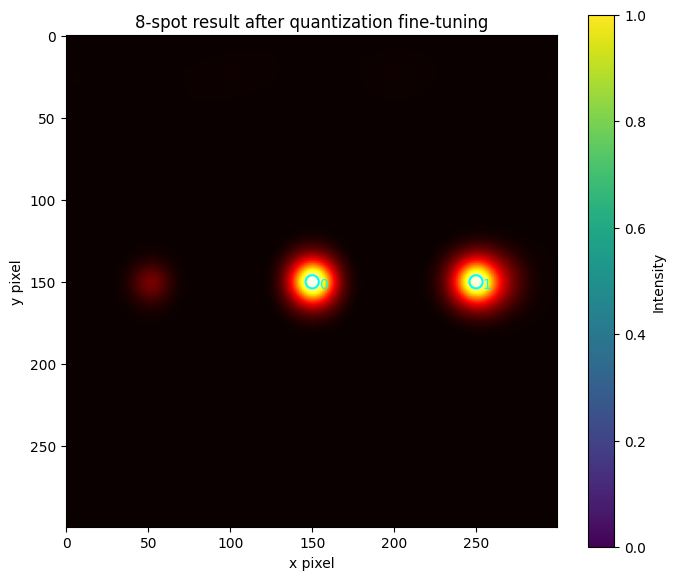

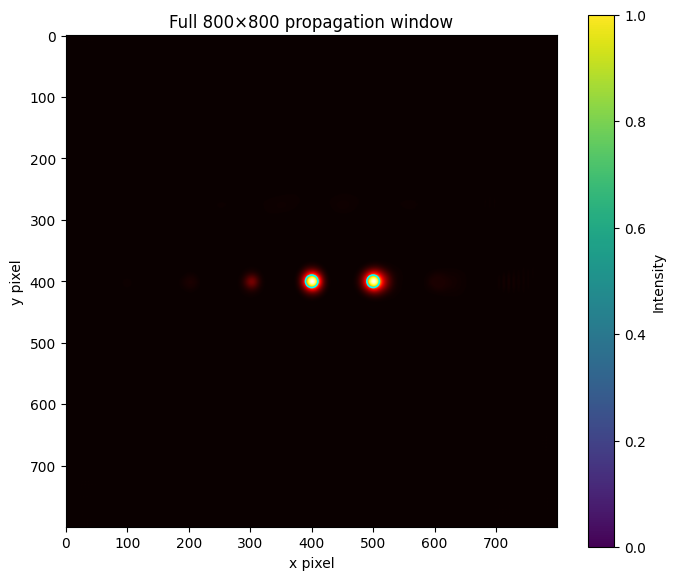


每个光斑积分能量:
Spot 0: 1829.1791
Spot 1: 1822.3601

每个光斑核心能量:
Core 0: 456.2896
Core 1: 448.0940

质心偏差:
Spot 0: dx=0.007 um, dy=-0.030 um
Spot 1: dx=0.046 um, dy=-0.031 um

积分能量均匀性:
max/min: 1.0037418343930984
相对标准差: 0.0018674234019933995
中心/外围平均: 1.0037418343930984

核心亮度均匀性:
max/min: 1.0182900214211608
相对标准差: 0.009062137367296804

能量效率:
目标区域效率: 0.3651539
禁止区域能量比例: 0.20128186

文件已保存:
phase_realVCSEL_spots8_continuous_rad.npy
phase_realVCSEL_spots8_8level_rad.npy
phase_realVCSEL_spots8_8level.bmp
实际8级灰度值: [  0  32  64  96 128 160 192 224]


In [7]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# ==========================================
# 0. 基本参数：8光斑专用
# ==========================================
num_spots = 2
num_levels = 8
sigma = 4.0
efficiency = 0.55
r_out = 100.0
angle_offset_deg = 0.0

N_phase = 100
plate_pitch = 100
N_design = 200

Ns = 800
margin = (Ns - N_design) // 2

dx = 1.0
lam = 0.850
z = 1000.0
n = 1.0

n_epochs = 3000
quantization_start_epoch = 2500
random_seed = 42

vcsel_path = Path("vcsel_150um_ComplexField_100x100.npy")

print("相位板尺寸:", N_phase, "×", N_phase)
print("板中心间距:", plate_pitch, "um")
print("传播窗口:", Ns, "×", Ns)
print("连续相位训练:", quantization_start_epoch, "轮")
print("8级量化微调:", n_epochs - quantization_start_epoch, "轮")

# ==========================================
# 1. 加载VCSEL复光场
# ==========================================
if not vcsel_path.exists():
    raise FileNotFoundError(f"找不到VCSEL文件：{vcsel_path.resolve()}")

E_vcsel_100 = np.load(vcsel_path)

if E_vcsel_100.shape != (N_phase, N_phase):
    raise ValueError(f"VCSEL尺寸应为100×100，实际为{E_vcsel_100.shape}")
if not np.iscomplexobj(E_vcsel_100):
    raise ValueError("VCSEL输入必须是复数光场。")
if not np.all(np.isfinite(E_vcsel_100)):
    raise ValueError("VCSEL输入包含NaN或Inf。")

E_vcsel_100 = E_vcsel_100.astype(np.complex64)

# 当前训练左上角相位板
phase_x0 = margin
phase_y0 = margin

E_in_np = np.zeros((Ns, Ns), dtype=np.complex64)
E_in_np[
    phase_y0:phase_y0 + N_phase,
    phase_x0:phase_x0 + N_phase
] = E_vcsel_100

E_in_initial = tf.constant(E_in_np, dtype=tf.complex64)

total_input_energy = float(np.sum(np.abs(E_vcsel_100) ** 2))
target_total_energy = total_input_energy * efficiency
expected_spot_energy = target_total_energy / num_spots

# 四板公共交点
center_x = margin + N_phase
center_y = margin + N_phase

phase_center_x = phase_x0 + N_phase / 2
phase_center_y = phase_y0 + N_phase / 2

print("相位板中心:", phase_center_x, phase_center_y)
print("四板公共交点:", center_x, center_y)
print("偏转量:", center_x - phase_center_x, center_y - phase_center_y, "um")
print("输入总能量:", total_input_energy)
print("目标总能量:", target_total_energy)
print("单光斑目标能量:", expected_spot_energy)

# ==========================================
# 2. 角谱传播函数
# ==========================================
fx = np.fft.fftfreq(Ns, d=dx).astype(np.float32)
fy = np.fft.fftfreq(Ns, d=dx).astype(np.float32)
FX, FY = np.meshgrid(fx, fy)

root = (n / lam) ** 2 - FX ** 2 - FY ** 2
propagating = root >= 0

kz = np.zeros_like(root, dtype=np.float32)
kz[propagating] = 2.0 * np.pi * np.sqrt(root[propagating])

H = np.zeros((Ns, Ns), dtype=np.complex64)
H[propagating] = np.exp(1j * kz[propagating] * z).astype(np.complex64)
H_tf = tf.constant(H, dtype=tf.complex64)

@tf.function
def propagate(field):
    return tf.signal.ifft2d(tf.signal.fft2d(field) * H_tf)

# ==========================================
# 3. 生成8个目标光斑：中心1个+外围7个
# ==========================================
x = np.arange(Ns, dtype=np.float32)
y = np.arange(Ns, dtype=np.float32)
X, Y = np.meshgrid(x, y)

centers = [(center_x, center_y)]

for i in range(num_spots - 1):
    angle = np.deg2rad(
        angle_offset_deg + i * 360.0 / (num_spots - 1)
    )
    cx = center_x + r_out * np.cos(angle)
    cy = center_y + r_out * np.sin(angle)
    centers.append((cx, cy))

print("\n目标光斑坐标:")
for i, (cx, cy) in enumerate(centers):
    print(
        f"Spot {i}: ({cx:.2f}, {cy:.2f}), "
        f"相对中心=({cx-center_x:.2f}, {cy-center_y:.2f})"
    )

ideal_intensity = np.zeros((Ns, Ns), dtype=np.float32)

for cx, cy in centers:
    ideal_intensity += np.exp(
        -((X - cx) ** 2 + (Y - cy) ** 2) / (2.0 * sigma ** 2)
    ).astype(np.float32)

ideal_intensity /= np.sum(ideal_intensity) + 1e-12
ideal_intensity *= target_total_energy

ideal_intensity_tf = tf.constant(ideal_intensity, dtype=tf.float32)
ideal_amp_tf = tf.sqrt(ideal_intensity_tf + 1e-12)

# ==========================================
# 4. 建立目标、核心和背景mask
# ==========================================
R_spot = 12.0
R_core = 5.0

spot_masks = []
core_masks = []

for cx, cy in centers:
    spot_masks.append(
        np.where(
            (X - cx) ** 2 + (Y - cy) ** 2 <= R_spot ** 2,
            1.0, 0.0
        ).astype(np.float32)
    )
    core_masks.append(
        np.where(
            (X - cx) ** 2 + (Y - cy) ** 2 <= R_core ** 2,
            1.0, 0.0
        ).astype(np.float32)
    )

spot_masks = np.asarray(spot_masks, dtype=np.float32)
core_masks = np.asarray(core_masks, dtype=np.float32)

spot_masks_tf = tf.constant(spot_masks, dtype=tf.float32)
core_masks_tf = tf.constant(core_masks, dtype=tf.float32)

# 每个光斑单独的高斯形状目标
ideal_spot_patterns = []

for i, (cx, cy) in enumerate(centers):
    G = np.exp(
        -((X - cx) ** 2 + (Y - cy) ** 2) / (2.0 * sigma ** 2)
    ).astype(np.float32)

    G *= spot_masks[i]
    G /= np.sum(G) + 1e-12
    ideal_spot_patterns.append(G)

ideal_spot_patterns_tf = tf.constant(
    np.asarray(ideal_spot_patterns, dtype=np.float32),
    dtype=tf.float32
)

target_mask = np.clip(
    np.sum(spot_masks, axis=0), 0.0, 1.0
).astype(np.float32)

background_mask = (1.0 - target_mask).astype(np.float32)

target_mask_tf = tf.constant(target_mask, dtype=tf.float32)
background_mask_tf = tf.constant(background_mask, dtype=tf.float32)

# 质心坐标
X_tf = tf.constant(X, dtype=tf.float32)
Y_tf = tf.constant(Y, dtype=tf.float32)

target_cx_tf = tf.constant(
    [c[0] for c in centers], dtype=tf.float32
)
target_cy_tf = tf.constant(
    [c[1] for c in centers], dtype=tf.float32
)

target_cx_np = np.asarray([c[0] for c in centers])
target_cy_np = np.asarray([c[1] for c in centers])

# ==========================================
# 4.1 禁止区域和近场背景
# ==========================================
R_allowed = r_out + 35.0
R_near = r_out + 25.0

allowed_region = np.where(
    (X - center_x) ** 2 + (Y - center_y) ** 2 <= R_allowed ** 2,
    1.0, 0.0
).astype(np.float32)

near_region = np.where(
    (X - center_x) ** 2 + (Y - center_y) ** 2 <= R_near ** 2,
    1.0, 0.0
).astype(np.float32)

forbidden_mask = (
    (1.0 - allowed_region) * background_mask
).astype(np.float32)

near_background_mask = (
    near_region * background_mask
).astype(np.float32)

forbidden_mask_tf = tf.constant(forbidden_mask, dtype=tf.float32)
near_background_mask_tf = tf.constant(
    near_background_mask, dtype=tf.float32
)

print("\nR_spot:", R_spot)
print("R_core:", R_core)
print("R_near:", R_near)
print("R_allowed:", R_allowed)

# ==========================================
# 5. 初始化相位板和优化器
# ==========================================
tf.random.set_seed(random_seed)
np.random.seed(random_seed)

phase_plate = tf.Variable(
    tf.random.uniform(
        shape=(N_phase, N_phase),
        minval=0.0,
        maxval=2.0 * np.pi,
        dtype=tf.float32
    ),
    name="phase_plate"
)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.005)

paddings = tf.constant([
    [phase_y0, Ns - phase_y0 - N_phase],
    [phase_x0, Ns - phase_x0 - N_phase]
])

phase_step = tf.constant(
    2.0 * np.pi / num_levels,
    dtype=tf.float32
)

# 前期False：连续相位
# 后期True：8级量化感知训练
use_quantization = tf.Variable(
    False,
    trainable=False,
    dtype=tf.bool
)

# ==========================================
# 5.1 Loss权重
# ==========================================
weight_shape = 0.5
weight_spot_shape = 600.0
weight_each_energy = 100.0
weight_uniform = 300.0
weight_center_balance = 150.0
weight_core_uniform = 250.0
weight_centroid = 100.0
weight_background = 20.0
weight_bg_peak = 30.0
weight_forbidden = 50.0
weight_forbidden_peak = 80.0
weight_near_background = 80.0

# ==========================================
# 6. 单步训练函数
# ==========================================
@tf.function
def train_step():
    with tf.GradientTape() as tape:
        phase_snapshot = tf.identity(phase_plate)

        phase_continuous = tf.math.floormod(
            phase_plate, 2.0 * np.pi
        )

        phase_quantized = tf.round(
            phase_continuous / phase_step
        ) * phase_step

        phase_quantized = tf.math.floormod(
            phase_quantized, 2.0 * np.pi
        )

        # 前向使用量化值，反向使用连续梯度
        phase_ste = phase_continuous + tf.stop_gradient(
            phase_quantized - phase_continuous
        )

        phase_used = tf.cond(
            use_quantization,
            lambda: phase_ste,
            lambda: phase_continuous
        )

        complex_phase = tf.complex(
            tf.cos(phase_used),
            tf.sin(phase_used)
        )

        complex_phase_padded = tf.pad(
            complex_phase,
            paddings,
            mode="CONSTANT",
            constant_values=0.0
        )

        E_modulated = E_in_initial * complex_phase_padded
        U_out = propagate(E_modulated)
        I_out = tf.square(tf.abs(U_out))
        total_output_energy = tf.reduce_sum(I_out)

        # Loss 1：目标区域整体形状
        amp_out = tf.sqrt(I_out + 1e-12)

        loss_shape = tf.reduce_sum(
            tf.square(
                (amp_out - ideal_amp_tf) * target_mask_tf
            )
        ) / (tf.reduce_sum(target_mask_tf) + 1e-12)

        # Loss 2：每个光斑积分能量
        spot_energies = tf.reduce_sum(
            I_out[None, :, :] * spot_masks_tf,
            axis=[1, 2]
        )

        loss_each_energy = tf.reduce_mean(
            tf.square(
                (spot_energies - expected_spot_energy)
                / (expected_spot_energy + 1e-12)
            )
        )

        # Loss 3：光斑局部高斯形状
        I_spots = I_out[None, :, :] * spot_masks_tf

        I_spots_norm = I_spots / (
            tf.reduce_sum(
                I_spots,
                axis=[1, 2],
                keepdims=True
            ) + 1e-12
        )

        loss_spot_shape = tf.reduce_mean(
            tf.reduce_sum(
                tf.square(
                    I_spots_norm - ideal_spot_patterns_tf
                ),
                axis=[1, 2]
            )
        )

        # Loss 4：积分能量均匀性
        mean_spot_energy = tf.reduce_mean(spot_energies)

        loss_uniform = tf.reduce_mean(
            tf.square(
                (spot_energies - mean_spot_energy)
                / (mean_spot_energy + 1e-12)
            )
        )

        # Loss 5：中心与外围光斑平衡
        center_spot_energy = spot_energies[0]
        outer_mean_energy = tf.reduce_mean(spot_energies[1:])

        loss_center_balance = tf.square(
            (center_spot_energy - outer_mean_energy)
            / (outer_mean_energy + 1e-12)
        )

        # Loss 6：核心区域亮度均匀性
        core_energies = tf.reduce_sum(
            I_out[None, :, :] * core_masks_tf,
            axis=[1, 2]
        )

        mean_core_energy = tf.reduce_mean(core_energies)

        loss_core_uniform = tf.reduce_mean(
            tf.square(
                (core_energies - mean_core_energy)
                / (mean_core_energy + 1e-12)
            )
        )

        # Loss 7：光斑质心位置
        spot_sum = tf.reduce_sum(
            I_spots, axis=[1, 2]
        ) + 1e-12

        pred_cx = tf.reduce_sum(
            I_spots * X_tf[None, :, :],
            axis=[1, 2]
        ) / spot_sum

        pred_cy = tf.reduce_sum(
            I_spots * Y_tf[None, :, :],
            axis=[1, 2]
        ) / spot_sum

        loss_centroid = tf.reduce_mean(
            tf.square((pred_cx - target_cx_tf) / sigma)
            + tf.square((pred_cy - target_cy_tf) / sigma)
        )

        # Loss 8：全局背景
        background_intensity = I_out * background_mask_tf
        background_energy = tf.reduce_sum(background_intensity)

        loss_background = background_energy / (
            total_output_energy + 1e-12
        )

        # Loss 9：背景Top-K强像素
        background_flat = tf.reshape(background_intensity, [-1])

        top_bg_values = tf.nn.top_k(
            background_flat, k=500
        ).values

        loss_bg_peak = tf.reduce_mean(top_bg_values) / (
            mean_spot_energy + 1e-12
        )

        # Loss 10：远处禁止区域
        forbidden_intensity = I_out * forbidden_mask_tf
        forbidden_energy = tf.reduce_sum(forbidden_intensity)

        loss_forbidden = forbidden_energy / (
            total_output_energy + 1e-12
        )

        target_peak = tf.reduce_max(I_out * target_mask_tf)

        loss_forbidden_peak = tf.reduce_max(
            forbidden_intensity
        ) / (target_peak + 1e-12)

        # Loss 11：目标组内部雾状背景
        near_background_energy = tf.reduce_sum(
            I_out * near_background_mask_tf
        )

        loss_near_background = near_background_energy / (
            total_output_energy + 1e-12
        )

        loss = (
            weight_shape * loss_shape
            + weight_spot_shape * loss_spot_shape
            + weight_each_energy * loss_each_energy
            + weight_uniform * loss_uniform
            + weight_center_balance * loss_center_balance
            + weight_core_uniform * loss_core_uniform
            + weight_centroid * loss_centroid
            + weight_background * loss_background
            + weight_bg_peak * loss_bg_peak
            + weight_forbidden * loss_forbidden
            + weight_forbidden_peak * loss_forbidden_peak
            + weight_near_background * loss_near_background
        )

        tf.debugging.check_numerics(
            loss, "训练Loss出现NaN或Inf"
        )

    grads = tape.gradient(loss, [phase_plate])

    if grads[0] is None:
        raise RuntimeError("相位板梯度为None，请检查传播函数。")

    tf.debugging.check_numerics(
        grads[0], "相位板梯度出现NaN或Inf"
    )

    clipped_grads, _ = tf.clip_by_global_norm(
        grads, 5.0
    )

    optimizer.apply_gradients(
        zip(clipped_grads, [phase_plate])
    )

    phase_plate.assign(
        tf.math.floormod(
            phase_plate, 2.0 * np.pi
        )
    )

    return (
        loss,
        loss_each_energy,
        loss_uniform,
        loss_center_balance,
        loss_core_uniform,
        loss_centroid,
        loss_background,
        loss_bg_peak,
        loss_forbidden,
        loss_forbidden_peak,
        loss_near_background,
        loss_spot_shape,
        spot_energies,
        core_energies,
        pred_cx,
        pred_cy,
        phase_snapshot
    )

# ==========================================
# 7. 开始训练
# ==========================================
best_score = np.inf
best_phase = None
best_epoch = -1

best_continuous_score = np.inf
best_continuous_phase = None

loss_history = []
spot_energy_history = []
core_energy_history = []

for epoch in range(n_epochs):
    # 进入8级量化微调阶段
    if epoch == quantization_start_epoch:
        use_quantization.assign(True)
        optimizer.learning_rate.assign(0.001)

        # 最终必须选择量化阶段的最优结果
        best_score = np.inf
        best_phase = None
        best_epoch = -1

        print("\n======================================")
        print("开始8级量化感知微调")
        print("学习率调整为:", float(optimizer.learning_rate.numpy()))
        print("最终相位将从量化阶段重新选择")
        print("======================================\n")

    result = train_step()

    if epoch % 10 == 0:
        (
            loss_t,
            each_t,
            uniform_t,
            center_balance_t,
            core_uniform_t,
            centroid_t,
            background_t,
            bg_peak_t,
            forbidden_t,
            forbidden_peak_t,
            near_bg_t,
            spot_shape_t,
            spot_energies_t,
            core_energies_t,
            pred_cx_t,
            pred_cy_t,
            phase_snapshot_t
        ) = result

        loss_v = float(loss_t.numpy())
        each_v = float(each_t.numpy())
        uniform_v = float(uniform_t.numpy())
        center_balance_v = float(center_balance_t.numpy())
        core_uniform_v = float(core_uniform_t.numpy())
        centroid_v = float(centroid_t.numpy())
        background_v = float(background_t.numpy())
        bg_peak_v = float(bg_peak_t.numpy())
        forbidden_v = float(forbidden_t.numpy())
        forbidden_peak_v = float(forbidden_peak_t.numpy())
        near_bg_v = float(near_bg_t.numpy())
        spot_shape_v = float(spot_shape_t.numpy())

        spot_energies_v = spot_energies_t.numpy()
        core_energies_v = core_energies_t.numpy()
        pred_cx_v = pred_cx_t.numpy()
        pred_cy_v = pred_cy_t.numpy()

        current_score = (
            5.0 * each_v
            + 12.0 * uniform_v
            + 8.0 * center_balance_v
            + 12.0 * core_uniform_v
            + 8.0 * centroid_v
            + 2.0 * background_v
            + 2.0 * bg_peak_v
            + 3.0 * forbidden_v
            + 6.0 * forbidden_peak_v
            + 3.0 * near_bg_v
            + 1.0 * spot_shape_v
        )

        # 连续训练阶段单独保存，用于排查
        if epoch < quantization_start_epoch:
            if np.isfinite(current_score) and current_score < best_continuous_score:
                best_continuous_score = current_score
                best_continuous_phase = phase_snapshot_t.numpy().copy()

        # 量化阶段保存最终打印相位
        else:
            if np.isfinite(current_score) and current_score < best_score:
                best_score = current_score
                best_phase = phase_snapshot_t.numpy().copy()
                best_epoch = epoch

        loss_history.append(loss_v)
        spot_energy_history.append(spot_energies_v.copy())
        core_energy_history.append(core_energies_v.copy())

        if epoch % 50 == 0:
            stage = "量化微调" if epoch >= quantization_start_epoch else "连续相位"

            print(
                f"Epoch {epoch:4d} [{stage}] | "
                f"Loss:{loss_v:.5f} | "
                f"EachE:{each_v:.5f} | "
                f"Uniform:{uniform_v:.5f} | "
                f"CoreUniform:{core_uniform_v:.5f} | "
                f"CenterBalance:{center_balance_v:.5f} | "
                f"Centroid:{centroid_v:.5f} | "
                f"ForbiddenPeak:{forbidden_peak_v:.5f}"
            )
            print("SpotE:", np.round(spot_energies_v, 2))
            print("CoreE:", np.round(core_energies_v, 2))
            print(
                "Centroid dx:",
                np.round(pred_cx_v - target_cx_np, 2)
            )
            print(
                "Centroid dy:",
                np.round(pred_cy_v - target_cy_np, 2)
            )

print("\n训练完成！")

if best_phase is None:
    raise RuntimeError(
        "8级量化微调阶段没有保存有效相位，请检查训练日志。"
    )

phase_plate.assign(best_phase)

print("量化阶段best epoch:", best_epoch)
print("量化阶段best score:", best_score)
print("连续阶段best score:", best_continuous_score)

# ==========================================
# 8. 使用最终8级相位重新传播
# ==========================================
phase_continuous_final = tf.math.floormod(
    phase_plate, 2.0 * np.pi
)

phase_quantized_final = tf.round(
    phase_continuous_final / phase_step
) * phase_step

phase_quantized_final = tf.math.floormod(
    phase_quantized_final, 2.0 * np.pi
)

complex_phase_final = tf.complex(
    tf.cos(phase_quantized_final),
    tf.sin(phase_quantized_final)
)

complex_phase_padded = tf.pad(
    complex_phase_final,
    paddings,
    mode="CONSTANT",
    constant_values=0.0
)

E_modulated = E_in_initial * complex_phase_padded
U_out_final = propagate(E_modulated)
I_out_final = tf.square(tf.abs(U_out_final)).numpy()

# ==========================================
# 9. 显示公共交点周围300×300
# ==========================================
N_display = 300
display_half = N_display // 2

display_x0 = int(center_x - display_half)
display_y0 = int(center_y - display_half)

I_show = I_out_final[
    display_y0:display_y0 + N_display,
    display_x0:display_x0 + N_display
]

plt.figure(figsize=(7, 6))
plt.imshow(I_show, cmap="hot", origin="upper")

for i, (cx, cy) in enumerate(centers):
    cx_show = cx - display_x0
    cy_show = cy - display_y0

    plt.scatter(
        cx_show, cy_show,
        s=90,
        facecolors="none",
        edgecolors="cyan",
        linewidths=1.5
    )
    plt.text(
        cx_show + 4,
        cy_show + 4,
        str(i),
        color="cyan"
    )

plt.title("8-spot result after quantization fine-tuning")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.colorbar(label="Intensity")
plt.tight_layout()
plt.show()

# ==========================================
# 10. 显示整个800×800传播窗口
# ==========================================
plt.figure(figsize=(7, 6))
plt.imshow(I_out_final, cmap="hot", origin="upper")

for cx, cy in centers:
    plt.scatter(
        cx, cy,
        s=80,
        facecolors="none",
        edgecolors="cyan",
        linewidths=1.2
    )

plt.title("Full 800×800 propagation window")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.colorbar(label="Intensity")
plt.tight_layout()
plt.show()

# ==========================================
# 11. 最终能量和质心统计
# ==========================================
spot_energy_values = []
core_energy_values = []
centroid_x_values = []
centroid_y_values = []

for i, (cx, cy) in enumerate(centers):
    I_spot_np = I_out_final * spot_masks[i]

    spot_energy = np.sum(I_spot_np)
    core_energy = np.sum(I_out_final * core_masks[i])

    pred_x = np.sum(I_spot_np * X) / (spot_energy + 1e-12)
    pred_y = np.sum(I_spot_np * Y) / (spot_energy + 1e-12)

    spot_energy_values.append(spot_energy)
    core_energy_values.append(core_energy)
    centroid_x_values.append(pred_x)
    centroid_y_values.append(pred_y)

spot_energy_values = np.asarray(spot_energy_values, dtype=np.float64)
core_energy_values = np.asarray(core_energy_values, dtype=np.float64)
centroid_x_values = np.asarray(centroid_x_values)
centroid_y_values = np.asarray(centroid_y_values)

print("\n每个光斑积分能量:")
for i, value in enumerate(spot_energy_values):
    print(f"Spot {i}: {value:.4f}")

print("\n每个光斑核心能量:")
for i, value in enumerate(core_energy_values):
    print(f"Core {i}: {value:.4f}")

print("\n质心偏差:")
for i, (cx, cy) in enumerate(centers):
    print(
        f"Spot {i}: "
        f"dx={centroid_x_values[i]-cx:.3f} um, "
        f"dy={centroid_y_values[i]-cy:.3f} um"
    )

spot_max = np.max(spot_energy_values)
spot_min = np.min(spot_energy_values)
spot_mean = np.mean(spot_energy_values)

core_max = np.max(core_energy_values)
core_min = np.min(core_energy_values)
core_mean = np.mean(core_energy_values)

print("\n积分能量均匀性:")
print("max/min:", spot_max / (spot_min + 1e-12))
print(
    "相对标准差:",
    np.std(spot_energy_values) / (spot_mean + 1e-12)
)
print(
    "中心/外围平均:",
    spot_energy_values[0]
    / (np.mean(spot_energy_values[1:]) + 1e-12)
)

print("\n核心亮度均匀性:")
print("max/min:", core_max / (core_min + 1e-12))
print(
    "相对标准差:",
    np.std(core_energy_values) / (core_mean + 1e-12)
)

total_output_energy = np.sum(I_out_final)
target_output_energy = np.sum(I_out_final * target_mask)
forbidden_output_energy = np.sum(I_out_final * forbidden_mask)

print("\n能量效率:")
print(
    "目标区域效率:",
    target_output_energy / (total_output_energy + 1e-12)
)
print(
    "禁止区域能量比例:",
    forbidden_output_energy / (total_output_energy + 1e-12)
)

# ==========================================
# 12. 保存连续相位和8级打印相位
# ==========================================
phase_continuous_np = np.mod(
    best_phase, 2.0 * np.pi
).astype(np.float32)

phase_quantized_np = phase_quantized_final.numpy().astype(np.float32)

np.save(
    "phase_realVCSEL_spots8_continuous_rad.npy",
    phase_continuous_np
)

np.save(
    "phase_realVCSEL_spots8_8level_rad.npy",
    phase_quantized_np
)

# 相位等级：0～7
level_index = np.rint(
    phase_quantized_np / (2.0 * np.pi) * num_levels
).astype(np.int32) % num_levels

# 正确8级灰度：0、32、64、96、128、160、192、224
gray_8level = (
    level_index * (256 // num_levels)
).astype(np.uint8)

Image.fromarray(gray_8level, mode="L").save(
    "phase_realVCSEL_spots8_8level.bmp"
)

print("\n文件已保存:")
print("phase_realVCSEL_spots8_continuous_rad.npy")
print("phase_realVCSEL_spots8_8level_rad.npy")
print("phase_realVCSEL_spots8_8level.bmp")
print("实际8级灰度值:", np.unique(gray_8level))

In [8]:
# ==========================================
# 4. 保存真实光场训练得到的相位板 + 可视化
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 建立输出文件夹
save_dir = f"real_vcsel_train_spots{num_spots}"
os.makedirs(save_dir, exist_ok=True)

# 1. 取出训练后的相位
phase_final = phase_plate.numpy().astype(np.float32)   # 100x100, 单位 rad
phase_final = np.mod(phase_final, 2*np.pi)

print("相位板 shape:", phase_final.shape)
print("相位范围:", phase_final.min(), phase_final.max())


# ==========================================
# 3. 保存 0~255 连续灰度相位图
# ==========================================

phase_gray = np.round(phase_final / (2*np.pi) * 255).astype(np.uint8)

Image.fromarray(phase_gray).save(
    os.path.join(save_dir, f"phase_realVCSEL_spots{num_spots}_gray.bmp")
)

# ==========================================
# 4. 保存 8 级量化相位图
# 灰度等级：0, 32, 64, 96, 128, 160, 192, 224
# ==========================================

levels = np.array([0, 32, 64, 96, 128, 160, 192, 224], dtype=np.uint8)

idx = np.floor(phase_gray / 32).astype(int)
idx = np.clip(idx, 0, 7)

phase_8level = levels[idx]

Image.fromarray(phase_8level).save(
    os.path.join(save_dir, f"phase_realVCSEL_spots{num_spots}_8level.bmp")
)

print("✅ 相位保存完成！")
print("保存文件夹:", save_dir)
print("8级灰度值:", np.unique(phase_8level))

相位板 shape: (100, 100)
相位范围: 0.0004272461 6.282688
✅ 相位保存完成！
保存文件夹: real_vcsel_train_spots2
8级灰度值: [  0  32  64  96 128 160 192 224]
